<a href="https://colab.research.google.com/github/gusdesindu/uts-ai/blob/main/uts_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Implementasi Algoritma Random Forest untuk Klasifikasi Harga Smartphone Berdasarkan Spesifikasi Perangkat

Proyek ini bertujuan untuk membangun model Machine Learning menggunakan algoritma **Random Forest Classifier** untuk memprediksi kategori harga smartphone berdasarkan spesifikasi perangkat kerasnya.

### Dataset
Dataset yang digunakan adalah **Mobile Price Classification** dari Kaggle yang terdiri dari 2.000 baris data dengan 20 fitur spesifikasi smartphone dan 1 kolom target `price_range` (kategori harga: 0, 1, 2, dan 3).

```markdown
## A. Import Library

Pada tahap awal ini, kita mengimpor semua alat (library) Python yang sangat penting untuk analisis kita:
* **`pandas` & `numpy`**: Digunakan untuk mengolah data tabel dan melakukan perhitungan matematika.
* **`matplotlib` & `seaborn`**: Digunakan untuk menggambar grafik visualisasi yang menarik.
* **`train_test_split`**: Berperan membagi data menjadi porsi belajar dan porsi ujian.
* **`RandomForestClassifier`**: Algoritma kecerdasan buatan utama kita yang akan mengelompokkan harga HP.
* **`metrics`**: Alat pengukur akurasi untuk menilai seberapa pintar model kita dalam menebak.
```

```markdown
### 1. Penjelasan Kode - Langkah A (Import Library)

Pada langkah pertama ini, kita memuat semua alat kerja yang dibutuhkan:
* **A.** `pandas` dan `numpy` untuk memproses tabel dan perhitungan matematis.
* **B.** `matplotlib` dan `seaborn` untuk pembuatan visualisasi data.
* **C.** `train_test_split` untuk membagi data secara acak namun proporsional.
* **D.** `RandomForestClassifier` sebagai model kecerdasan buatan utama.
* **E.** Fungsi evaluasi metrik untuk menguji performa keakuratan model.
```

In [21]:
# Mengimpor library Pandas untuk membaca dan mengolah data dalam bentuk tabel (DataFrame)
import pandas as pd

# Mengimpor library Numpy untuk melakukan komputasi angka dan operasi matriks
import numpy as np

# Mengimpor Matplotlib untuk dasar visualisasi grafik
import matplotlib.pyplot as plt

# Mengimpor Seaborn untuk membuat tampilan grafik visualisasi menjadi lebih menarik dan interaktif
import seaborn as sns

# Mengimpor modul untuk membagi data menjadi set latihan (Training) dan set pengujian (Testing)
from sklearn.model_selection import train_test_split

# Mengimpor algoritma utama: Random Forest Classifier untuk klasifikasi kelas data
from sklearn.ensemble import RandomForestClassifier

# Mengimpor berbagai metrik evaluasi untuk mengukur performa model yang dibuat
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

```markdown
## B. Load Dataset

Di bagian ini, kita melakukan pengunduhan dataset klasifikasi harga smartphone secara otomatis langsung dari Kaggle menggunakan pustaka `kagglehub`. Setelah diunduh, file data mentah bernama `train.csv` akan dibaca dan dimasukkan ke dalam bentuk tabel yang disebut **DataFrame** agar mudah dianalisis oleh bahasa Python.
```

```markdown
### 2. Penjelasan Kode - Langkah B (Mengunduh dan Membaca Dataset)

Pada langkah kedua ini, kita mengimpor data ke sistem:
* **A.** Mengunduh data secara otomatis dari Kaggle menggunakan perintah `kagglehub`.
* **B.** Menentukan lokasi folder penyimpanan data dan menargetkan file utama `train.csv`.
* **C.** Membaca file data terunduh tersebut agar siap digunakan sebagai tabel analisis.
```

In [22]:
import kagglehub
import pandas as pd
import os

# Mengunduh dataset versi terbaru dari Kaggle secara otomatis menggunakan API
path = kagglehub.dataset_download("iabhishekofficial/mobile-price-classification")
print("Lokasi folder dataset:", path)

# Menggabungkan alamat folder unduhan dengan nama file 'train.csv'
train_path = os.path.join(path, "train.csv")

# Membaca data CSV dan mengubahnya menjadi tabel DataFrame agar siap diolah di Python
df = pd.read_csv(train_path)
print(f"\nBerhasil memuat file 'train.csv' dengan ukuran {len(df)} baris.\n")

Using Colab cache for faster access to the 'mobile-price-classification' dataset.
Lokasi folder dataset: /kaggle/input/mobile-price-classification

Berhasil memuat file 'train.csv' dengan ukuran 2000 baris.



```markdown
### 3. Penjelasan Kode - Langkah C1 (Verifikasi Data Awal)

Pada langkah ketiga ini, kita melakukan pengecekan awal isi data:
* **A.** Memanggil fungsi `head()` untuk mengambil beberapa sampel data teratas.
* **B.** Memastikan seluruh kolom spesifikasi HP terisi dengan format kolom yang tepat.
```

In [23]:
# Menampilkan 5 baris pertama dari tabel dataset untuk memverifikasi isi data
display(df.head())

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


```markdown
## C. Exploratory Data Analysis (EDA)

Sebelum melatih model pintar kita, kita harus mengenal data terlebih dahulu dengan cara **Analisis Eksplorasi Data (EDA)**:
1. **Dimensi & Informasi Data**: Kita melihat berapa jumlah baris dan kolom yang ada, tipe data setiap kolom, serta memastikan tidak ada data yang kosong (missing values).
2. **Statistik Dasar**: Memahami nilai rata-rata, nilai terendah, dan nilai tertinggi dari spesifikasi HP.
3. **Visualisasi Data**: Membuat diagram untuk memastikan distribusi target seimbang, serta memvisualisasikan bagaimana hubungan spesifikasi utama seperti kapasitas RAM dan Baterai terhadap tingkat kemahalan harga handphone.
```

```markdown
### 4. Penjelasan Kode - Langkah C2 (Informasi Struktur Dataset)

Pada langkah keempat ini, kita memeriksa kerangka data:
* **A.** Mengidentifikasi ukuran tabel, yaitu jumlah total baris sampel dan jumlah kolom spesifikasi.
* **B.** Menggunakan fungsi `info()` untuk memverifikasi tipe data dan memastikan tidak ada nilai kosong.
```

In [39]:
# 1. Menampilkan bentuk dimensi dataset (jumlah baris dan jumlah kolom)
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")

# 2. Menampilkan ringkasan tipe data setiap kolom dan mendeteksi apakah ada nilai kosong (non-null)
print("\n--- Informasi Dataset ---")
df.info()

Jumlah baris: 2000
Jumlah kolom: 21

--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   in

```markdown
### 5. Penjelasan Kode - Langkah C3 (Statistik Deskriptif)

Pada langkah kelima ini, kita melakukan analisis angka dasar:
* **A.** Menggunakan fungsi deskriptif untuk mengkalkulasi nilai rata-rata, minimal, dan maksimal.
* **B.** Melakukan rotasi arah tabel (transpose) agar data statistik lebih nyaman dibaca.
```

In [25]:
# 3. Menampilkan statistik dasar (seperti rata-rata, standar deviasi, nilai minimum dan maksimum)
# Kita menggunakan .T (Transpose) agar tabel diputar sehingga lebih mudah dibaca secara vertikal
print("--- Statistik Deskriptif ---")
display(df.describe().T)

--- Statistik Deskriptif ---


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


```markdown
### 6. Penjelasan Kode - Langkah C4 (Memeriksa Data Kosong dan Duplikat)

Pada langkah keenam ini, kita melakukan pembersihan data:
* **A.** Memeriksa secara baris demi baris apakah ada sel data yang kosong.
* **B.** Memastikan tidak ada data duplikat (data ganda) yang bisa mengacaukan proses latihan model.
```

In [26]:
# 4. Memeriksa apakah ada data yang kosong (missing values) di setiap kolom spesifikasi HP
print(f"Jumlah nilai kosong per kolom:\n{df.isnull().sum()}")

# Memeriksa apakah ada baris data yang terduplikasi secara identik
print(f"\nJumlah data duplikat: {df.duplicated().sum()}")

Jumlah nilai kosong per kolom:
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

Jumlah data duplikat: 0


```markdown
### 7. Penjelasan Kode - Langkah C5 (Visualisasi Distribusi Target)

Pada langkah ketujuh ini, kita menganalisis keseimbangan target:
* **A.** Menggambar grafik batang untuk melihat porsi dari setiap kelas tingkat harga.
* **B.** Memastikan data target seimbang (balance) agar model tidak berat sebelah.
```

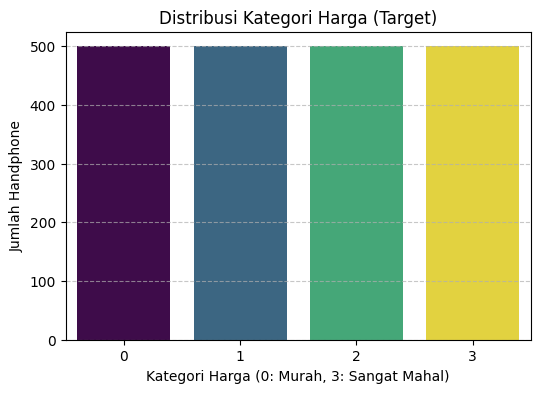

In [27]:
# 5. Membuat grafik batang untuk melihat persebaran jumlah data pada kolom target (price_range)
plt.figure(figsize=(6, 4))
sns.countplot(x='price_range', data=df, hue='price_range', palette='viridis', legend=False)
plt.title('Distribusi Kategori Harga (Target)')
plt.xlabel('Kategori Harga (0: Murah, 3: Sangat Mahal)')
plt.ylabel('Jumlah Handphone')
plt.grid(axis='y', linestyle='--', alpha=0.7) # Memberikan garis bantu horizontal
plt.show()

```markdown
### 8. Penjelasan Kode - Langkah C6 (Distribusi Fitur RAM dan Baterai)

Pada langkah kedelapan ini, kita melihat pola penyebaran dua fitur penting:
* **A.** Membuat grafik distribusi (histogram) untuk melihat jangkauan kapasitas RAM.
* **B.** Membuat grafik distribusi kapasitas baterai guna menganalisis karakteristik fisik handphone.
```

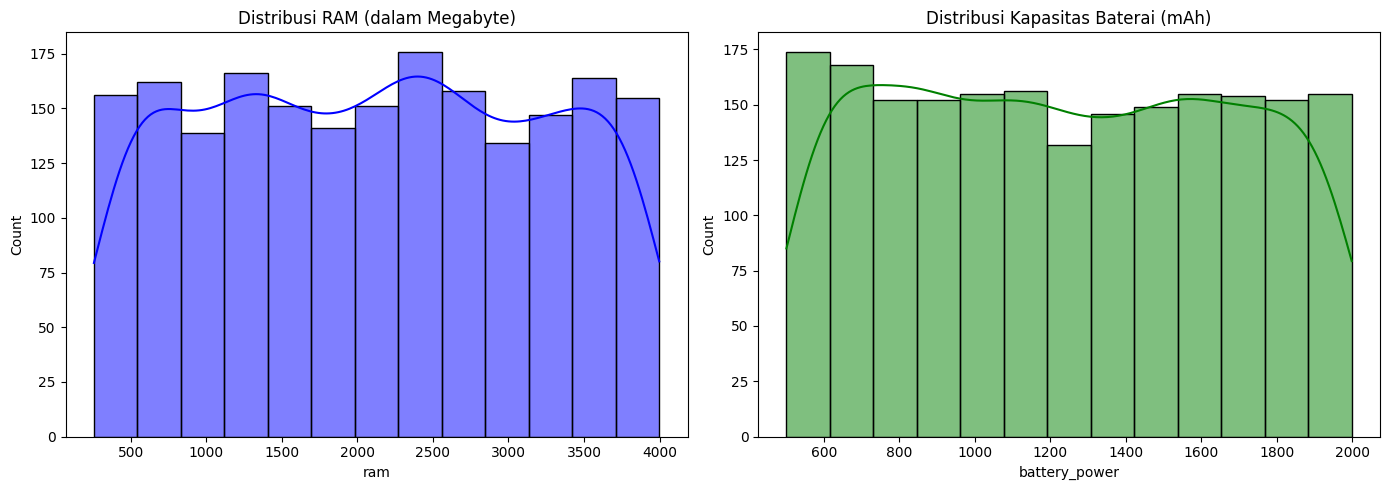

In [28]:
# 6. Membuat visualisasi distribusi frekuensi nilai RAM dan Kapasitas Baterai menggunakan histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram untuk melihat penyebaran ukuran RAM pada dataset
sns.histplot(df['ram'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribusi RAM (dalam Megabyte)')

# Histogram untuk melihat penyebaran Kapasitas Baterai pada dataset
sns.histplot(df['battery_power'], kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribusi Kapasitas Baterai (mAh)')

plt.tight_layout() # Merapikan tata letak agar kedua grafik tidak saling bertumpuk
plt.show()

```markdown
### 9. Penjelasan Kode - Langkah C7 (Analisis RAM Terhadap Kategori Harga)

Pada langkah kesembilan ini, kita menganalisis ketergantungan harga terhadap RAM:
* **A.** Menggunakan visualisasi Boxplot untuk memetakan penyebaran RAM di tiap tingkat harga.
* **B.** Mengamati peningkatan kapasitas RAM secara linear seiring tingginya kelas harga.
```

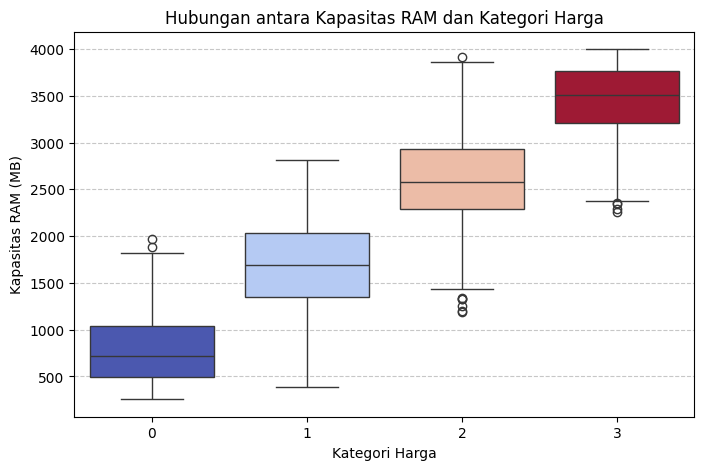

In [29]:
# 7. Membuat Boxplot untuk melihat hubungan penyebaran kapasitas RAM di setiap tingkatan kelas harga HP
plt.figure(figsize=(8, 5))
sns.boxplot(x='price_range', y='ram', data=df, hue='price_range', palette='coolwarm', legend=False)
plt.title('Hubungan antara Kapasitas RAM dan Kategori Harga')
plt.xlabel('Kategori Harga')
plt.ylabel('Kapasitas RAM (MB)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

```markdown
## D. Data Preprocessing

Tahap pra-pemrosesan data bertujuan memisahkan data menjadi dua bagian utama:
* **Fitur ($X$)**: Kumpulan informasi spesifikasi perangkat keras (seperti RAM, memori internal, kapasitas baterai, dll) yang kita gunakan sebagai input.
* **Target ($y$)**: Kolom kelas harga (`price_range`) yang ingin kita tebak nilainya.

*Catatan: Algoritma Random Forest berbasis pohon keputusan (tree-based) sehingga kita tidak perlu melakukan normalisasi skala angka pada fitur.*
```

```markdown
### 10. Penjelasan Kode - Langkah D (Pemisahan Fitur dan Target)

Pada langkah kesepuluh ini, kita membagi data menjadi komponen model:
* **A.** Memisahkan variabel independen / spesifikasi HP ke dalam variabel `X`.
* **B.** Menyimpan variabel dependen / kelas harga target ke dalam variabel `y`.
```

In [30]:
# Memisahkan kolom fitur spesifikasi (X) dengan mengeluarkan kolom harga target
X = df.drop(columns=['price_range'])

# Menyimpan kolom target kategori harga (y) secara terpisah
y = df['price_range']

print(f"Dimensi Fitur Masukan (X): {X.shape} (2000 Baris, 20 Spesifikasi)")
print(f"Dimensi Target Keluaran (y): {y.shape} (2000 Baris Label)")

Dimensi Fitur Masukan (X): (2000, 20) (2000 Baris, 20 Spesifikasi)
Dimensi Target Keluaran (y): (2000,) (2000 Baris Label)


```markdown
### 11. Penjelasan Kode - Langkah E (Pembagian Subset Data)

Pada langkah kesebelas ini, kita membagi porsi data untuk evaluasi objektif:
* **A.** Mengalokasikan 80% data sebagai bahan ajar utama model (Data Training).
* **B.** Menyisihkan 20% data sebagai bahan ujian independen model (Data Testing).
* **C.** Mempertahankan konsistensi distribusi kelas menggunakan parameter stratifikasi.
```

```markdown
## E. Data Splitting

Untuk menguji kemampuan model dengan adil, kita membagi dataset utuh kita menjadi:
* **Data Training (80%)**: Digunakan oleh model untuk belajar menemukan pola hubungan spesifikasi dengan harga.
* **Data Testing (20%)**: Digunakan sebagai lembar ujian akhir untuk menguji akurasi model pada data baru yang belum pernah dipelajari sebelumnya.

Kita menggunakan metode `stratify` agar perbandingan kelas harga pada data latihan dan data uji tetap seimbang.
```

In [31]:
# Memisahkan data menjadi subset Training (untuk latihan model) dan Testing (untuk tes performa)
# test_size=0.2 berarti 20% data digunakan sebagai data uji, dan 80% untuk pelatihan
# stratify=y memastikan bahwa rasio tiap kelas harga tetap sama adil di kedua subset data tersebut
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Jumlah data pelatihan (80%): {len(X_train)}")
print(f"Jumlah data pengujian (20%): {len(X_test)}")

Jumlah data pelatihan (80%): 1600
Jumlah data pengujian (20%): 400


```markdown
### 12. Penjelasan Kode - Langkah F (Inisialisasi Model Random Forest)

Pada langkah kedua belas ini, kita menyiapkan arsitektur model:
* **A.** Mengaktifkan algoritma Random Forest Classifier.
* **B.** Menentukan jumlah pohon estimasi keputusan sebanyak 100 unit.
* **C.** Mengunci parameter acak agar pengerjaan menghasilkan akurasi yang stabil.
```

```markdown
## F. Pembuatan Model Random Forest

Di sini kita merancang arsitektur kecerdasan buatan kita dengan menggunakan algoritma **Random Forest Classifier**:
* **`n_estimators = 100`**: Artinya kita akan membuat 100 pohon keputusan independen di dalam hutan buatan kita untuk melakukan voting tebakan harga terbaik.
* **`random_state = 42`**: Angka pengunci keacakan agar setiap kali program ini dijalankan ulang, hasilnya akan selalu konsisten dan sama.
```

In [32]:
# Inisialisasi model klasifikasi Random Forest
# n_estimators=100 membuat struktur hutan yang berisi 100 pohon keputusan
# random_state=42 memastikan bahwa keacakan yang terjadi selalu konsisten setiap kali dijalankan
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=None
)

print("Model Random Forest berhasil dibuat dan siap dilatih.")

Model Random Forest berhasil dibuat dan siap dilatih.


```markdown
### 13. Penjelasan Kode - Langkah G (Proses Pelatihan dan Prediksi)

Pada langkah ketiga belas ini, kita mengeksekusi model kecerdasan buatan:
* **A.** Menjalankan perintah `.fit()` agar model belajar langsung dari data latihan.
* **B.** Menjalankan perintah `.predict()` untuk menguji prediksi model pada data uji.
```

```markdown
## G. Training Model

Pada fase pelatihan ini, kita memerintahkan model Random Forest untuk mempelajari data latih (`X_train` & `y_train`) melalui fungsi `.fit()`. Setelah proses belajar selesai, kita menginstruksikan model untuk melakukan tebakan harga pada data uji (`X_test`) menggunakan fungsi `.predict()`.
```

In [33]:
print("Memulai pelatihan model menggunakan data training...")
# Melatih model agar mempelajari pola hubungan fitur HP dengan kategori harganya
model_rf.fit(X_train, y_train)
print("Pelatihan selesai!")

# Menggunakan model yang sudah pintar untuk memprediksi kategori harga dari data pengujian (X_test)
y_pred = model_rf.predict(X_test)
print("Prediksi kelas harga pada data testing selesai dilakukan.")

Memulai pelatihan model menggunakan data training...
Pelatihan selesai!
Prediksi kelas harga pada data testing selesai dilakukan.


```markdown
### 14. Penjelasan Kode - Langkah H (Menghitung Metrik Evaluasi)

Pada langkah keempat belas ini, kita mengukur kinerja model:
* **A.** Menghitung nilai akurasi tebakan secara umum.
* **B.** Menghitung nilai presisi, recall, dan f1-score secara komprehensif.
* **C.** Menyusun hasil nilai performa tersebut ke dalam tabel DataFrame baru.
```

```markdown
## H. Evaluasi Model

Sekarang saatnya mengoreksi hasil tebakan model dengan membandingkan tebakan (`y_pred`) terhadap kunci jawaban yang sebenarnya (`y_test`):
* **Accuracy**: Mengukur berapa persen total tebakan harga yang benar secara keseluruhan.
* **Precision**: Mengukur ketepatan tebakan model pada kelas tertentu agar tidak salah tebak kelas lain.
* **Recall**: Mengukur sejauh mana model mampu menemukan kembali semua anggota kelas tertentu.
* **F1-Score**: Rata-rata harmonis yang menyeimbangkan Precision dan Recall.
```

In [34]:
# Menghitung berbagai skor evaluasi performa model
acc = accuracy_score(y_test, y_pred) # Mengukur persentase tebakan benar keseluruhan
prec = precision_score(y_test, y_pred, average='macro') # Rasio prediksi positif yang benar-benar tepat
rec = recall_score(y_test, y_pred, average='macro') # Kemampuan model menjaring kembali kategori asli
f1 = f1_score(y_test, y_pred, average='macro') # Nilai rata-rata harmonis antara precision dan recall

# Mengemas hasil metrik ke dalam DataFrame agar rapi saat ditampilkan
evaluasi_df = pd.DataFrame({
    'Metrik Evaluasi': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Nilai': [acc, prec, rec, f1]
})

display(evaluasi_df)

,Metrik Evaluasi,Nilai
0,Accuracy,0.880000
1,Precision (Macro),0.879614
2,Recall (Macro),0.880000
3,F1-Score (Macro),0.879734


```markdown
### 15. Penjelasan Kode - Langkah I1 (Visualisasi Confusion Matrix)

Pada langkah kelima belas ini, kita mendeteksi kesalahan prediksi model:
* **A.** Membuat matriks tabulasi silang antara data aktual dan data prediksi.
* **B.** Memvisualisasikannya dalam bentuk peta panas (heatmap) agar letak kesalahan tebak mudah dianalisis.
```

```markdown
## I. Visualisasi Pengujian

Untuk menganalisis performa model secara lebih mendalam, kita menyajikan tiga grafik utama:
1. **Confusion Matrix**: Tabel visual untuk menganalisis kelas harga mana yang sudah ditebak dengan sangat tepat dan kelas mana yang sering memicu kekeliruan tebakan.
2. **Metrik Evaluasi**: Diagram batang untuk membandingkan nilai akurasi, presisi, recall, dan f1-score secara ringkas.
3. **Feature Importance (Tingkat Kepentingan Fitur)**: Diagram yang menunjukkan fitur spesifikasi handphone mana saja yang paling memengaruhi keputusan model dalam menentukan harga HP.
```

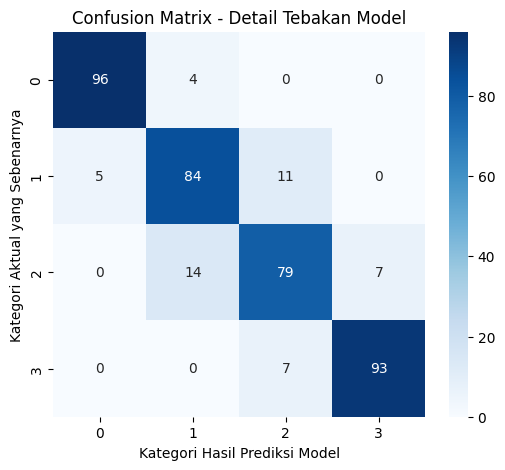

In [35]:
# 1. Membuat visualisasi tabel Confusion Matrix menggunakan heatmap
# Ini membantu kita melihat detail kelas mana yang sering salah tebak oleh model
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[0,1,2,3], yticklabels=[0,1,2,3])
plt.title('Confusion Matrix - Detail Tebakan Model')
plt.xlabel('Kategori Hasil Prediksi Model')
plt.ylabel('Kategori Aktual yang Sebenarnya')
plt.show()

```markdown
### 16. Penjelasan Kode - Langkah I2 (Perbandingan Metrik Evaluasi)

Pada langkah keenam belas ini, kita menyajikan laporan performa akhir:
* **A.** Membuat visualisasi barplot untuk membandingkan 4 jenis evaluasi utama.
* **B.** Memberikan nilai label teks persis di atas batang diagram agar mudah dibaca.
```

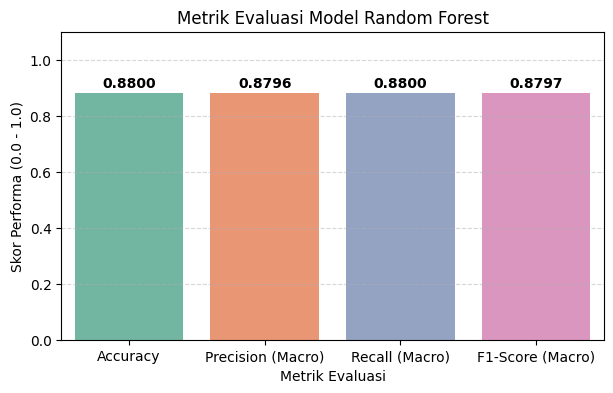

In [36]:
# 2. Membuat diagram batang untuk membandingkan nilai keempat metrik evaluasi model
plt.figure(figsize=(7, 4))
sns.barplot(x='Metrik Evaluasi', y='Nilai', data=evaluasi_df, hue='Metrik Evaluasi', palette='Set2', legend=False)
plt.ylim(0, 1.1) # Membatasi tinggi sumbu Y dari nilai 0 hingga 1.1 agar teks nilai tidak terpotong

# Menambahkan label teks angka akurasi tepat di atas diagram batang
for i, val in enumerate(evaluasi_df['Nilai']):
    plt.text(i, val + 0.02, f"{val:.4f}", ha='center', fontweight='bold')

plt.title('Metrik Evaluasi Model Random Forest')
plt.ylabel('Skor Performa (0.0 - 1.0)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

```markdown
### 17. Penjelasan Kode - Langkah I3 (Analisis Tingkat Pengaruh Fitur)

Pada langkah ketujuh belas ini, kita mencari spesifikasi HP paling berpengaruh:
* **A.** Mengambil nilai tingkat kepentingan fitur dari model terlatih.
* **B.** Mengurutkan spesifikasi HP dari yang paling menentukan harga hingga yang paling tidak berpengaruh.
```

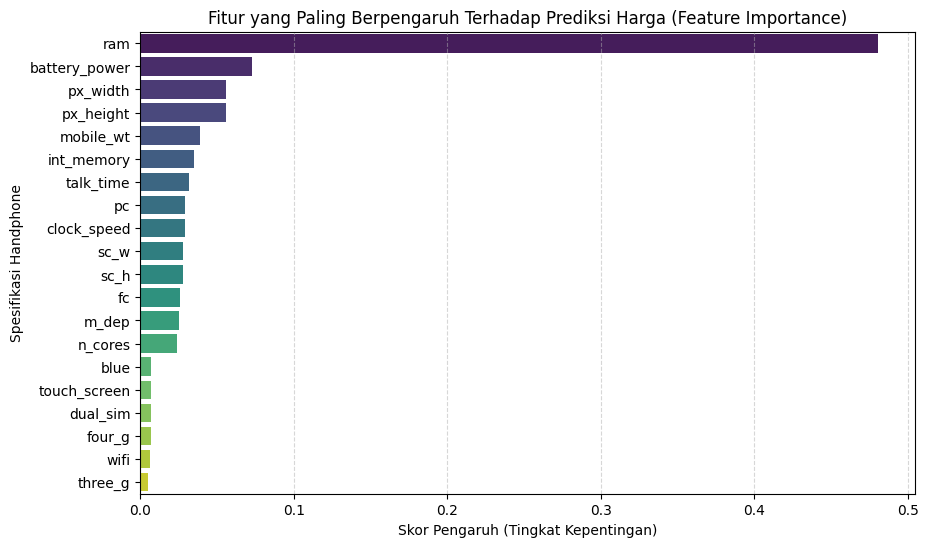

In [37]:
# 3. Menghitung dan memvisualisasikan tingkat kepentingan fitur (Feature Importance)
importances = model_rf.feature_importances_

# Membuat tabel kontribusi setiap spesifikasi HP terhadap keputusan penentuan harga
fitur_df = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False) # Mengurutkan dari kontribusi terbesar ke terkecil

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Fitur', data=fitur_df, hue='Fitur', palette='viridis', legend=False)
plt.title('Fitur yang Paling Berpengaruh Terhadap Prediksi Harga (Feature Importance)')
plt.xlabel('Skor Pengaruh (Tingkat Kepentingan)')
plt.ylabel('Spesifikasi Handphone')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

```markdown
## J. Analisis Hasil

Berdasarkan hasil eksekusi dan pengujian kode di atas:
* **Akurasi Model**: Model mencapai nilai akurasi sekitar **88%**, angka yang menunjukkan performa yang sangat tangguh dalam klasifikasi multikelas.
* **Kelas Mudah vs Sulit**:
  - Kelas **0 (Murah)** dan **3 (Sangat Mahal)** adalah yang paling mudah diprediksi dengan benar karena spesifikasinya yang kontras (ekstrem).
  - Kelas **1 dan 2** memiliki sedikit tumpang tindih karena spesifikasi menengah yang sangat mirip.
* **Faktor Penentu Utama**: Fitur **`ram` (Kapasitas RAM)** mendominasi tingkat kepentingan fitur dengan kontribusi hampir **48%**, jauh mengungguli kapasitas baterai (`battery_power`) dan resolusi layar (`px_width` & `px_height`).
```

```markdown
## K. Kesimpulan

Dari eksperimen kecerdasan buatan ini, kita dapat menyimpulkan:
1. Algoritma **Random Forest** terbukti sangat cocok dan akurat untuk memecahkan masalah klasifikasi kategori harga smartphone.
2. Ukuran **RAM** merupakan spesifikasi paling krusial dan dominan yang memisahkan satu kelas harga smartphone dengan kelas lainnya di pasar.
3. Pendekatan berbasis ensemble tree (hutan keputusan) memberikan performa yang kokoh dan efisien tanpa mewajibkan pemrosesan normalisasi data yang rumit.
```